In [2]:
%pip install scikit-learn xgboost
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

# 1. Öznitelik mühendisliğinden çıkan veriyi yükle
df = pd.read_csv('../data/processed/df_features.csv')
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])
df = df.sort_values('DATE_TIME').reset_index(drop=True)

# 2. Model girdileri (X) ve Hedef Değişken (y) belirleme
# Rapordaki formülasyona göre hedefimiz: AC_POWER (toplam üretilen güç)
target = 'AC_POWER'

features = [
    'IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE',
    'sin_time', 'cos_time', 'sin_day', 'cos_day',
    'ac_power_lag_1', 'ac_power_lag_2', 'ac_power_lag_4',
    'irradiation_lag_1', 'module_temp_lag_1',
    'ac_power_rolling_mean_1h', 'irradiation_rolling_mean_1h'
]

X = df[features]
y = df[target]

# 3. Kronolojik Bölme (%80 Train, %20 Test)
split_idx = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train, dates_test = df['DATE_TIME'].iloc[:split_idx], df['DATE_TIME'].iloc[split_idx:]

print(f"Eğitim Verisi Boyutu: {X_train.shape}")
print(f"Test Verisi Boyutu  : {X_test.shape}")
print(f"Eğitim Tarih Aralığı: {dates_train.min()} -> {dates_train.max()}")
print(f"Test Tarih Aralığı  : {dates_test.min()} -> {dates_test.max()}")


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.2 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.2 kB ? eta -:--:--
     -------------------------------------- 61.2/61.2 kB 407.4 kB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
    --------------------------------------- 0.1/8.3 MB 1.2 MB/s eta 0:00:07
    --------------------------------------- 0.1/8.3 MB 1.2 MB/s eta 0:00:07
    --------------------------------------- 0.2/8.3 MB 857.5 kB/s eta 0:00:10
    --------------------------------------- 0.2/8.3 MB 857.5 kB/s eta 0:00:10
   - -------------------------------------- 0.3/8.3 MB 1.0 MB/s eta 0:00:08
   - -------------------------------------- 0.3/8.3 MB 1.0 MB/s eta 0:00:08
   -- -----------------------------

In [3]:
# 1. XGBoost Regresörünü Tanımla ve Eğit
model_xgb = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)

# 2. Test Seti Üzerinde Tahmin Al
y_pred = model_xgb.predict(X_test)
# Üretim fiziksel olarak negatif olamaz, 0'ın altındaki küçük değerleri sıfırlayalım
y_pred = np.clip(y_pred, 0, None)

# 3. Rapor Metriklerinin Hesaplanması
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- MODEL BAŞARI METRİKLERİ (XGBoost Baseline) ---")
print(f"RMSE (Kök Ortalama Kare Hata) : {rmse:.3f} kW")
print(f"MAE  (Ortalama Mutlak Hata)   : {mae:.3f} kW")
print(f"R²   (Belirlilik Katsayısı)   : {r2:.4f}")

--- MODEL BAŞARI METRİKLERİ (XGBoost Baseline) ---
RMSE (Kök Ortalama Kare Hata) : 429.124 kW
MAE  (Ortalama Mutlak Hata)   : 213.892 kW
R²   (Belirlilik Katsayısı)   : 0.9971


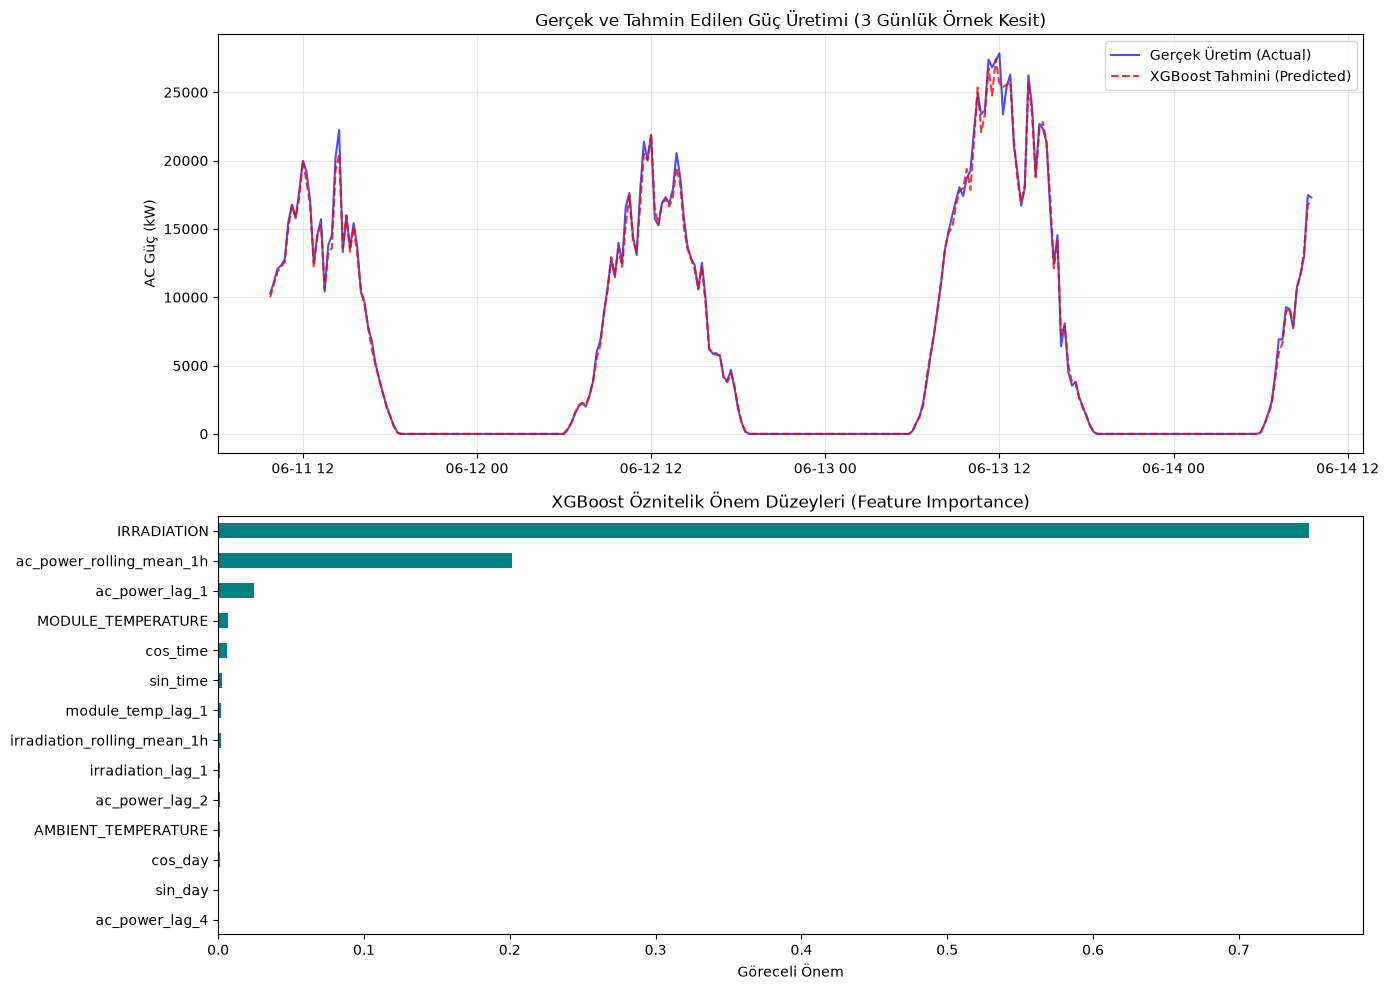

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. Grafik: Gerçek vs Tahmin Karşılaştırması (İlk 3 gün)
# Grafiği net görebilmek için test kümesinden ilk 3 günlük (yaklaşık 288 veri noktası) kesiti çizdirelim
sample_len = 96 * 3 
axes[0].plot(dates_test.iloc[:sample_len], y_test.iloc[:sample_len], label='Gerçek Üretim (Actual)', color='blue', alpha=0.7)
axes[0].plot(dates_test.iloc[:sample_len], y_pred[:sample_len], label='XGBoost Tahmini (Predicted)', color='red', linestyle='--', alpha=0.8)
axes[0].set_title('Gerçek ve Tahmin Edilen Güç Üretimi (3 Günlük Örnek Kesit)')
axes[0].set_ylabel('AC Güç (kW)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Grafik: Öznitelik Önem Dereceleri (Feature Importance)
importance = pd.Series(model_xgb.feature_importances_, index=features).sort_values(ascending=True)
importance.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('XGBoost Öznitelik Önem Düzeyleri (Feature Importance)')
axes[1].set_xlabel('Göreceli Önem')

plt.tight_layout()
plt.show()